# P2-f2 — GARCH(1,1): fit and convergence check (no forecasting yet)

Question: does GARCH(1,1) MLE converge to a sensible, stable optimum on every asset and every fitting window?

Fitting windows follow the annual walk-forward folds (see `README.md`). Each fold's fit uses returns dated ≤ 31 Dec of Y−1, with an expanding window from 2019:

| Fold | Fit on returns | Role of the fold |
|---|---|---|
| 2021 | 2019 → 2020 | Train |
| 2022 | 2019 → 2021 | Train |
| 2023 | 2019 → 2022 | Train |
| 2024 | 2019 → 2023 | Test |
| 2025 | 2019 → 2024 | Test |
| 2026 | 2019 → 2025 | Test (Jan–Sep) |

- Returns: r_t = 100 · `r` from `yz_data/<SYM>-yz-1d.csv` (the same file HAR-YZ uses), in %, as `GARCH.md` §3.1 recommends. Variances are in %², the same units as the HAR notebook.
- Mean: **zero** (`mean='Zero'`), so σ²_{t+1} forecasts E[r²_{t+1}], the same quantity as the provisional target `r2_next`.
- Distribution: **normal** (the regular case). `GARCH.md` §3 fixes (t distribution, solver change, more data) apply only if this fails to converge.
- Robustness is checked by restarting from several starting values. (`arch` 8.0.0 `fit()` has no `method` argument, so §3.3's solver switch isn't available anyway.)

In [1]:
import warnings
import numpy as np, pandas as pd, matplotlib.pyplot as plt
from pathlib import Path
from arch import arch_model
import arch

YZ = Path('yz_data')
ASSETS = ['BTC', 'ETH', 'QQQ', 'XAUUSD']
FOLDS = [2021, 2022, 2023, 2024, 2025, 2026]  # fit on returns dated <= 31 Dec of fold-1
C = {'realized': '#b4b2ab', 'sigma': '#2a78d6'}
plt.rcParams.update({'axes.spines.top': False, 'axes.spines.right': False,
                     'axes.grid': True, 'grid.color': '#e6e5e1', 'grid.linewidth': 0.6,
                     'figure.dpi': 110})
arch.__version__

'8.0.0'

In [2]:
def load_returns(sym):
    # same file as HAR-YZ, so returns, target and dates are identical by construction
    d = pd.read_csv(YZ / f'{sym}-yz-1d.csv', index_col=0)
    d.index = pd.to_datetime(d.index, utc=True)
    assert np.allclose(d.r.shift(-1)**2, d.r2_next, equal_nan=True), sym
    return (100 * d.r).dropna()

rets = {s: load_returns(s) for s in ASSETS}
{s: (r.index[0].date(), r.index[-1].date(), len(r)) for s, r in rets.items()}

{'BTC': (datetime.date(2019, 1, 2), datetime.date(2026, 10, 29), 2858),
 'ETH': (datetime.date(2019, 1, 2), datetime.date(2026, 10, 29), 2858),
 'QQQ': (datetime.date(2019, 1, 3), datetime.date(2026, 10, 29), 1967),
 'XAUUSD': (datetime.date(2019, 1, 3), datetime.date(2026, 10, 29), 2020)}

## Fit every (asset, fold)

Checked for each fit:
- `flag`: optimizer convergence flag (0 = converged) and the optimizer message.
- `warn`: any warning raised during the fit (convergence, scale, ...).
- `se_ok`: all standard errors finite and positive (a non-invertible Hessian shows up here).
- Stability: ω > 0, α ≥ 0, β ≥ 0, α + β < 1. `interior`: α + β < 0.999, i.e. the optimum is not sitting on arch's α + β ≤ 1 bound.
- Plausibility: half-life of a shock = ln 0.5 / ln(α+β) days; long-run daily vol √(ω / (1−α−β)) vs the sample std of the fitting window.

In [3]:
def fit_one(r, starting_values=None):
    m = arch_model(r, mean='Zero', vol='GARCH', p=1, q=1, dist='normal', rescale=False)
    with warnings.catch_warnings(record=True) as w:
        warnings.simplefilter('always')
        res = m.fit(disp='off', starting_values=starting_values)
    return res, sorted({type(x.message).__name__ for x in w})

def summarize(res, warns, r):
    p = res.params
    pers = p['alpha[1]'] + p['beta[1]']
    se = res.std_err
    return {
        'n': int(res.nobs), 'flag': res.convergence_flag,
        'msg': res.optimization_result.message, 'warn': ','.join(warns) or '-',
        'se_ok': bool(np.all(np.isfinite(se)) and np.all(se > 0)),
        'omega': p['omega'], 'alpha': p['alpha[1]'], 'beta': p['beta[1]'],
        'alpha+beta': pers,
        'half_life_d': np.log(0.5) / np.log(pers) if 0 < pers < 1 else np.inf,
        'lr_vol': np.sqrt(p['omega'] / (1 - pers)) if pers < 1 else np.inf,
        'sample_std': r.std(ddof=0), 'loglik': res.loglikelihood,
    }

fits, rows = {}, []
for s, r in rets.items():
    for fold in FOLDS:
        rf = r[r.index < pd.Timestamp(f'{fold}-01-01', tz='UTC')]
        res, warns = fit_one(rf)
        fits[s, fold] = (res, rf)
        rows.append({'asset': s, 'fold': fold, **summarize(res, warns, rf)})

tab = pd.DataFrame(rows).set_index(['asset', 'fold'])
tab.round(4)

n  flag                                   msg warn  se_ok  \
asset  fold                                                                 
BTC    2021   730     0  Optimization terminated successfully    -   True   
       2022  1095     0  Optimization terminated successfully    -   True   
       2023  1460     0  Optimization terminated successfully    -   True   
       2024  1825     0  Optimization terminated successfully    -   True   
       2025  2191     0  Optimization terminated successfully    -   True   
       2026  2556     0  Optimization terminated successfully    -   True   
ETH    2021   730     0  Optimization terminated successfully    -   True   
       2022  1095     0  Optimization terminated successfully    -   True   
       2023  1460     0  Optimization terminated successfully    -   True   
       2024  1825     0  Optimization terminated successfully    -   True   
       2025  2191     0  Optimization terminated successfully    -   True   
       2026  2556     0  Optimization terminated successfully    -   True   
QQQ    2021   504     0  Optimization terminated successfully    -   True   
       2022   756     0  Optimization terminated successfully    -   True   
       2023  1007     0  Optimization terminated successfully    -   True   
       2024  1257     0  Optimization terminated successfully    -   True   
       2025  1509     0  Optimization terminated successfully    -   True   
       2026  1759     0  Optimization terminated successfully    -   True   
XAUUSD 2021   516     0  Optimization terminated successfully    -   True   
       2022   774     0  Optimization terminated successfully    -   True   
       2023  1032     0  Optimization terminated successfully    -   True   
       2024  1289     0  Optimization terminated successfully    -   True   
       2025  1548     0  Optimization terminated successfully    -   True   
       2026  1806     0  Optimization terminated successfully    -   True   

              omega   alpha    beta  alpha+beta  half_life_d  lr_vol  \
asset  fold                                                            
BTC    2021  1.7561  0.1623  0.7608      0.9230       8.6564  4.7772   
       2022  1.4041  0.0798  0.8421      0.9219       8.5247  4.2403   
       2023  1.4732  0.0952  0.8167      0.9119       7.5149  4.0890   
       2024  0.9040  0.1202  0.8260      0.9462      12.5268  4.0980   
       2025  0.8225  0.1139  0.8310      0.9448      12.2178  3.8618   
       2026  0.6023  0.1184  0.8403      0.9587      16.4333  3.8186   
ETH    2021  1.8398  0.1231  0.8156      0.9387      10.9600  5.4792   
       2022  1.6411  0.1068  0.8410      0.9478      12.9264  5.6065   
       2023  1.8698  0.1152  0.8197      0.9350      10.3053  5.3614   
       2024  0.4408  0.0965  0.8912      0.9877      56.2345  5.9989   
       2025  0.5046  0.0940  0.8871      0.9811      36.4067  5.1726   
       2026  0.4753  0.0754  0.9036      0.9790      32.6598  4.7573   
QQQ    2021  0.0898  0.1860  0.7923      0.9783      31.5457  2.0324   
       2022  0.0865  0.1691  0.8003      0.9694      22.3130  1.6817   
       2023  0.0588  0.1389  0.8482      0.9871      53.4191  2.1364   
       2024  0.0535  0.1199  0.8620      0.9819      37.9540  1.7194   
       2025  0.0571  0.1155  0.8617      0.9771      29.9775  1.5802   
       2026  0.0662  0.1379  0.8374      0.9753      27.7525  1.6388   
XAUUSD 2021  0.0342  0.1447  0.8300      0.9747      27.1002  1.1645   
       2022  0.0398  0.0999  0.8580      0.9579      16.1205  0.9722   
       2023  0.0449  0.0840  0.8667      0.9507      13.7041  0.9546   
       2024  0.0473  0.0920  0.8540      0.9461      12.4996  0.9360   
       2025  0.0387  0.0776  0.8790      0.9566      15.6079  0.9437   
       2026  0.0484  0.0969  0.8541      0.9510      13.8069  0.9945   

             sample_std     loglik  
asset  fold                         
BTC    2021      3.9150 -2003.8993  
       2022      4.0234 -3050

In [4]:
# compact pass/fail view
chk = pd.DataFrame({
    'converged': tab.flag == 0,
    'no_warning': tab.warn == '-',
    'se_ok': tab.se_ok,
    'stationary': (tab['alpha+beta'] < 1) & (tab.omega > 0) & (tab.alpha >= 0) & (tab.beta >= 0),
    'interior': tab['alpha+beta'] < 0.999,  # arch bounds alpha+beta <= 1; an optimum on that bound is IGARCH, not an interior peak
})
chk['all_ok'] = chk.all(axis=1)
print('fits:', len(chk), '| all_ok:', int(chk.all_ok.sum()))
chk[~chk.all_ok] if (~chk.all_ok).any() else 'every fit passes'

fits: 24 | all_ok: 24


'every fit passes'

## Robustness: restart from several starting values

If MLE found the true peak, restarts from different (α, β) should land on the same log-likelihood and parameters.
For each fit, 9 restarts on α ∈ {0.03, 0.10, 0.20} × β ∈ {0.70, 0.85, 0.95}, with ω set so the starting long-run variance equals the sample variance.
`loglik_gain` > 0 means a restart beat the default fit (the default stopped short of the peak).

In [5]:
rob = []
for (s, fold), (res0, rf) in fits.items():
    var = rf.var(ddof=0)
    best, spread = res0, []
    for a in (0.03, 0.10, 0.20):
        for b in (0.70, 0.85, 0.95):
            res, _ = fit_one(rf, np.array([var * (1 - a - b), a, b]))
            if res.convergence_flag == 0:
                spread.append(res.params[['alpha[1]', 'beta[1]']].to_numpy())
                if res.loglikelihood > best.loglikelihood:
                    best = res
    spread = np.array(spread)
    rob.append({'asset': s, 'fold': fold,
                'restarts_converged': len(spread),
                'loglik_gain': best.loglikelihood - res0.loglikelihood,
                'alpha_range': np.ptp(spread[:, 0]), 'beta_range': np.ptp(spread[:, 1])})
rob = pd.DataFrame(rob).set_index(['asset', 'fold'])
rob.round(5)

restarts_converged  loglik_gain  alpha_range  beta_range
asset  fold                                                          
BTC    2021                   9          0.0      0.00002     0.00004
       2022                   9          0.0      0.00003     0.00003
       2023                   9          0.0      0.00002     0.00003
       2024                   9          0.0      0.00001     0.00001
       2025                   9          0.0      0.00002     0.00002
       2026                   9          0.0      0.00001     0.00001
ETH    2021                   9          0.0      0.00002     0.00003
       2022                   9          0.0      0.00001     0.00002
       2023                   9          0.0      0.00002     0.00003
       2024                   9          0.0      0.00002     0.00002
       2025                   9          0.0      0.00001     0.00001
       2026                   9          0.0      0.00001     0.00002
QQQ    2021                   9          0.0      0.00004     0.00003
       2022                   9          0.0      0.00001     0.00001
       2023                   9          0.0      0.00002     0.00002
       2024                   9          0.0      0.00001     0.00001
       2025                   9          0.0      0.00002     0.00001
       2026                   9          0.0      0.00002     0.00002
XAUUSD 2021                   9          0.0      0.00004     0.00004
       2022                   9          0.0      0.00002     0.00004
       2023                   9          0.0      0.00002     0.00005
       2024                   9          0.0      0.00002     0.00004
       2025                   9          0.0      0.00001     0.00001
       2026                   9          0.0      0.00002     0.00004

## Parameters by fold

How α, β and persistence move as the window grows.

In [6]:
tab[['alpha', 'beta', 'alpha+beta', 'half_life_d', 'lr_vol', 'sample_std']].round(3)

alpha   beta  alpha+beta  half_life_d  lr_vol  sample_std
asset  fold                                                           
BTC    2021  0.162  0.761       0.923        8.656   4.777       3.915
       2022  0.080  0.842       0.922        8.525   4.240       4.023
       2023  0.095  0.817       0.912        7.515   4.089       3.876
       2024  0.120  0.826       0.946       12.527   4.098       3.614
       2025  0.114  0.831       0.945       12.218   3.862       3.485
       2026  0.118  0.840       0.959       16.433   3.819       3.331
ETH    2021  0.123  0.816       0.939       10.960   5.479       4.918
       2022  0.107  0.841       0.948       12.926   5.606       5.184
       2023  0.115  0.820       0.935       10.305   5.361       5.045
       2024  0.097  0.891       0.988       56.235   5.999       4.642
       2025  0.094  0.887       0.981       36.407   5.173       4.452
       2026  0.075  0.904       0.979       32.660   4.757       4.377
QQQ    2021  0.186  0.792       0.978       31.546   2.032       1.694
       2022  0.169  0.800       0.969       22.313   1.682       1.552
       2023  0.139  0.848       0.987       53.419   2.136       1.683
       2024  0.120  0.862       0.982       37.954   1.719       1.585
       2025  0.115  0.862       0.977       29.977   1.580       1.520
       2026  0.138  0.837       0.975       27.752   1.639       1.526
XAUUSD 2021  0.145  0.830       0.975       27.100   1.165       0.985
       2022  0.100  0.858       0.958       16.120   0.972       0.941
       2023  0.084  0.867       0.951       13.704   0.955       0.939
       2024  0.092  0.854       0.946       12.500   0.936       0.918
       2025  0.078  0.879       0.957       15.608   0.944       0.923
       2026  0.097  0.854       0.951       13.807   0.994       0.967

## In-sample conditional volatility — fold 2024 fit (2019 → 2023)

σ_t from the fitted model vs |r_t|, daily %, log scale. This is an in-sample fit, not a forecast.

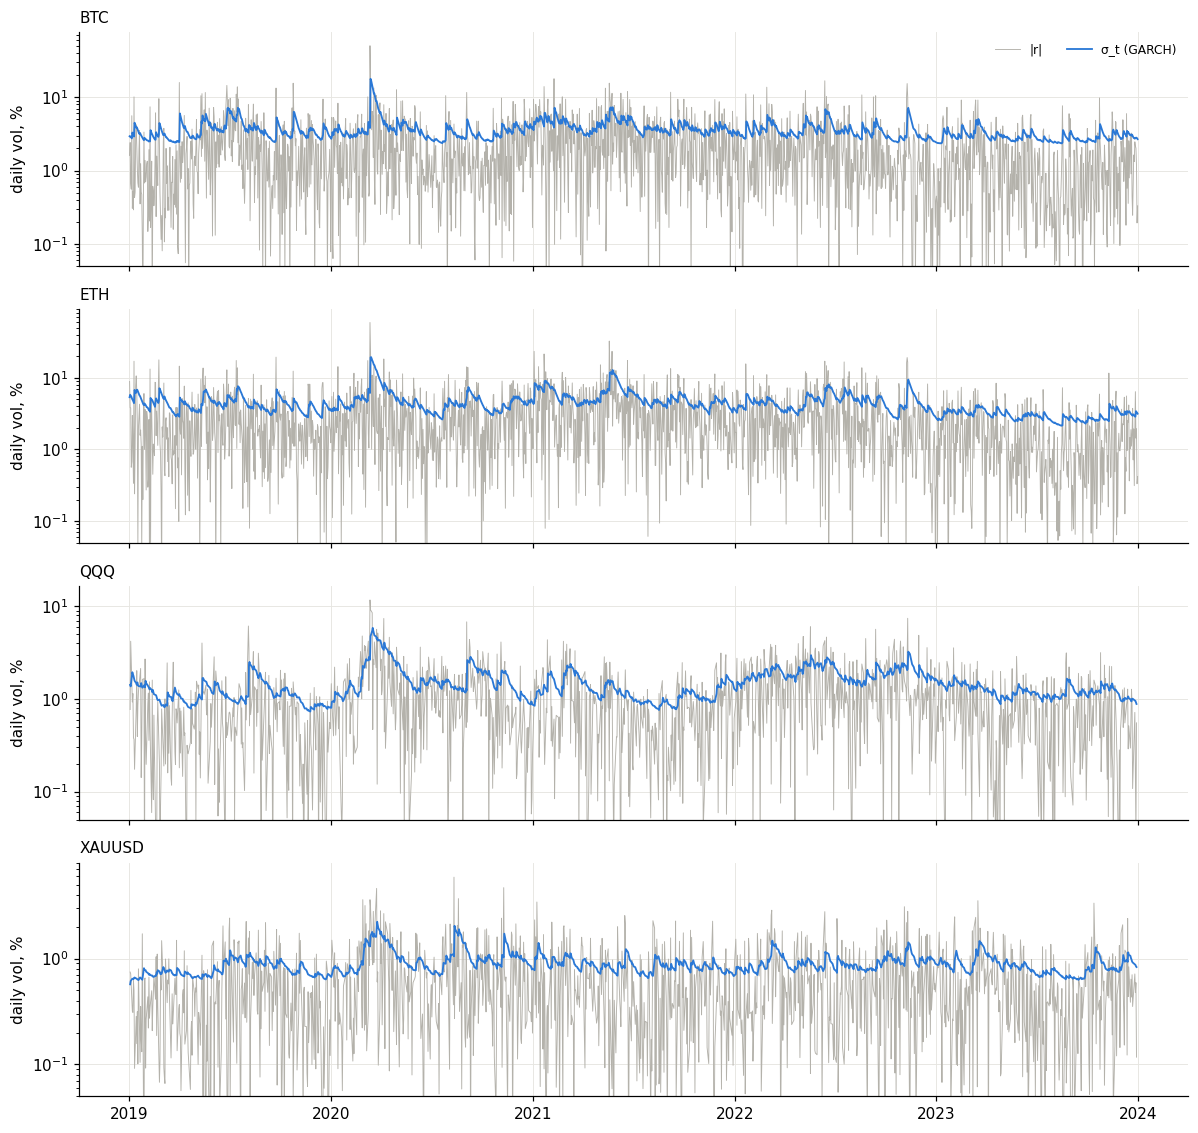

In [7]:
fig, axes = plt.subplots(len(ASSETS), 1, figsize=(11, 2.6 * len(ASSETS)), sharex=True)
for ax, s in zip(axes, ASSETS):
    res, rf = fits[s, 2024]
    ax.plot(rf.index, rf.abs().clip(lower=0.01), color=C['realized'], lw=0.6, label='|r|')
    ax.plot(rf.index, res.conditional_volatility, color=C['sigma'], lw=1.2, label='σ_t (GARCH)')
    ax.set_yscale('log'); ax.set_ylim(bottom=0.05)
    ax.set_title(s, loc='left', fontsize=10); ax.set_ylabel('daily vol, %')
axes[0].legend(loc='upper right', ncol=2, frameon=False, fontsize=8)
fig.tight_layout()

## Findings (run 2026-11-01)

**Normal GARCH(1,1) converges cleanly on all 24 fits** (4 assets × 6 folds, 2021–2026). Every fit has convergence flag 0, no warnings, finite standard errors, and α + β < 1 well inside the boundary (max 0.988). Restarts from 9 starting values land on the same log-likelihood (gain 0.0) and the same α, β (range ≤ 5e-5), so the peak is unique and found reliably. None of the `GARCH.md` §3 fixes are needed.

- **Parameters are in the ranges `GARCH.md` §3 quotes** (α 0.05–0.15, β 0.80–0.90). QQQ's α is a bit higher (0.12–0.19): it reacts faster to shocks.
- **Persistence α + β:** crypto 0.91–0.95 (half-life ~8–13 days), QQQ 0.97–0.99 (22–53 days), XAUUSD 0.95–0.98 (12–27 days). Crypto shocks fade faster than equity shocks under this model.
- **Fold to fold the parameters move gradually,** with one exception: ETH fold 2024 (fit 2019–2023), where persistence jumps 0.935 → 0.988 (half-life 10 → 56 days) and stays near 0.98 in folds 2025–26. Likely the calm, slowly declining 2023 volatility.
- **Long-run vol √(ω/(1−α−β)) is 5–30% above the sample std** in every fit (e.g. ETH 2024: 6.0% vs 4.6%). Observed, not yet explained. If it is real, GARCH forecasts drift back towards a level above recent volatility in calm periods. It matters less for one-day-ahead forecasts.

# Walk-forward forecasts: GARCH(1,1) vs HAR-YZ vs naive

Annual folds (see `README.md`): fold Y uses the parameters fitted on returns dated ≤ 31 Dec of Y−1, held fixed through Y.
With fixed parameters the model runs day by day over the full return series: σ²_{t+1} = ω + α r_t² + β σ²_t, which uses only returns up to t.
Each forecast is indexed by its origin (the close of day t) and targets day t+1, exactly like HAR-YZ.

| Split | Target dates | Folds |
|---|---|---|
| Train | 2021-01-01 → 2023-12-31 | 2021, 2022, 2023 |
| Test | 2024-01-01 → 2026-09-30 | 2024, 2025, 2026 (Jan–Sep) |

HAR-YZ forecasts (annual refit) come from `forecasts/<SYM>-HAR-YZ.csv`, written by `f2-HAR-YZ.ipynb`. Naive = `yz_var_22` carried forward. Target = `r2_next` (provisional). Units: %².

In [8]:
SPLITS = {'train': (pd.Timestamp('2021-01-01', tz='UTC'), pd.Timestamp('2024-01-01', tz='UTC')),
          'test':  (pd.Timestamp('2024-01-01', tz='UTC'), pd.Timestamp('2026-10-01', tz='UTC'))}
FC = Path('forecasts')

def load_yz(sym):
    d = pd.read_csv(YZ / f'{sym}-yz-1d.csv', index_col=0)
    d.index = pd.to_datetime(d.index, utc=True)
    d['target_date'] = d.index.to_series().shift(-1)
    return d

def garch_one_step(r, params):
    """σ²_{t+1} made at the close of t, for every t, under fixed params."""
    am = arch_model(r, mean='Zero', vol='GARCH', p=1, q=1, dist='normal', rescale=False)
    sig2 = am.fix(params).conditional_volatility ** 2
    return params['omega'] + params['alpha[1]'] * r**2 + params['beta[1]'] * sig2

# cross-check the recursion against arch's own 1-step forecast (one asset, one fold)
_p = fits['QQQ', 2024][0].params
_a = arch_model(rets['QQQ'], mean='Zero', rescale=False).fix(_p).forecast(horizon=1, start=0, reindex=False).variance['h.1']
assert np.allclose(garch_one_step(rets['QQQ'], _p), _a)

comp = {}
for s in ASSETS:
    yz = load_yz(s)
    har = pd.read_csv(FC / f'{s}-HAR-YZ.csv', index_col=0)
    har.index = pd.to_datetime(har.index, utc=True)
    rows = []
    for split, (a, b) in SPLITS.items():
        o = yz.index[(yz.target_date >= a) & (yz.target_date < b)]
        years = pd.DatetimeIndex(yz.target_date.loc[o]).year
        g = pd.Series(np.nan, index=o)
        for y in np.unique(years):
            g[years == y] = garch_one_step(rets[s], fits[s, y][0].params).reindex(o[years == y]).to_numpy()
        rows.append(pd.DataFrame({'split': split, 'fold': years, 'target_date': yz.target_date.loc[o],
                                  'naive': yz.yz_var_22.loc[o] * 1e4, 'HAR-YZ': har.h.reindex(o),
                                  'GARCH': g, 'realized': yz.r2_next.loc[o] * 1e4}, index=o))
    comp[s] = pd.concat(rows)
    assert comp[s][['naive', 'HAR-YZ', 'GARCH', 'realized']].notna().all().all(), s
    assert (pd.to_datetime(har.target_date, utc=True).reindex(comp[s].index) == comp[s].target_date).all(), s
    comp[s][['target_date', 'split', 'fold', 'GARCH']].rename(columns={'GARCH': 'h'}).to_csv(FC / f'{s}-GARCH11.csv')
{s: c.split.value_counts().to_dict() for s, c in comp.items()}

{'BTC': {'train': 1095, 'test': 1004},
 'ETH': {'train': 1095, 'test': 1004},
 'QQQ': {'train': 753, 'test': 689},
 'XAUUSD': {'train': 773, 'test': 710}}

In [9]:
MODELS = ['naive', 'HAR-YZ', 'GARCH']

def score(f):
    ok = (f[MODELS] > 0).all(axis=1)
    g, rv = f[ok], f.realized[ok]
    out = pd.DataFrame({m: {'RMSE': np.sqrt(np.mean((g[m] - rv)**2)),
                            'QLIKE': np.mean(np.log(g[m]) + rv / g[m])} for m in MODELS}).T
    out['RMSE/naive'] = out.RMSE / out.loc['naive', 'RMSE']
    out['ΔQLIKE vs naive'] = out.QLIKE - out.loc['naive', 'QLIKE']
    out['dropped'], out['n'] = int((~ok).sum()), int(ok.sum())
    return out

scores = pd.concat({(s, sp): score(c[c.split == sp]) for s, c in comp.items() for sp in SPLITS})
scores.round(3)

RMSE  QLIKE  RMSE/naive  ΔQLIKE vs naive  dropped     n
BTC    train naive   28.457  3.428       1.000            0.000        0  1095
             HAR-YZ  26.588  3.401       0.934           -0.027        0  1095
             GARCH   27.052  3.396       0.951           -0.032        0  1095
       test  naive   14.369  2.818       1.000            0.000        0  1004
             HAR-YZ  14.595  2.876       1.016            0.058        0  1004
             GARCH   14.356  2.796       0.999           -0.021        0  1004
ETH    train naive   56.003  3.791       1.000            0.000        0  1095
             HAR-YZ  52.831  3.855       0.943            0.063        0  1095
             GARCH   52.991  3.821       0.946            0.029        0  1095
       test  naive   31.516  3.631       1.000            0.000        0  1004
             HAR-YZ  30.857  3.534       0.979           -0.098        0  1004
             GARCH   30.615  3.545       0.971           -0.086        0  1004
QQQ    train naive    4.066  1.634       1.000            0.000        0   753
             HAR-YZ   4.232  1.678       1.041            0.044        0   753
             GARCH    4.220  1.679       1.038            0.045        0   753
       test  naive    6.887  1.477       1.000            0.000        0   689
             HAR-YZ   6.457  1.377       0.937           -0.100        0   689
             GARCH    6.872  1.430       0.998           -0.047        0   689
XAUUSD train naive    1.395  0.734       1.000            0.000        0   773
             HAR-YZ   1.379  0.694       0.989           -0.041        0   773
             GARCH    1.400  0.728       1.004           -0.007        0   773
       test  naive    4.766  1.459       1.000            0.000        0   710
             HAR-YZ   4.509  1.413       0.946           -0.047        0   710
             GARCH    4.521  1.417       0.949           -0.042        0   710

In [10]:
# ΔQLIKE per fold (lower = better). Last column: GARCH minus HAR-YZ (< 0 means GARCH better)
rows = {}
for s, c in comp.items():
    for y, g in c.groupby('fold'):
        q = score(g).QLIKE
        rows[s, y] = {'HAR-YZ − naive': q['HAR-YZ'] - q['naive'], 'GARCH − naive': q['GARCH'] - q['naive'],
                      'GARCH − HAR-YZ': q['GARCH'] - q['HAR-YZ'], 'split': g.split.iloc[0]}
pd.DataFrame(rows).T.rename_axis(['asset', 'fold']).round(3)

HAR-YZ − naive GARCH − naive GARCH − HAR-YZ  split
asset  fold                                                   
BTC    2021      -0.088047     -0.004303       0.083744  train
       2022       -0.08812     -0.092784      -0.004664  train
       2023       0.094969      0.000808       -0.09416  train
       2024       0.032543      0.000668      -0.031875   test
       2025       0.141427      0.020847       -0.12058   test
       2026       -0.01833     -0.107154      -0.088824   test
ETH    2021      -0.074367     -0.048212       0.026155  train
       2022      -0.088311     -0.070376       0.017935  train
       2023       0.352243      0.206632      -0.145611  train
       2024       0.017248     -0.001379      -0.018626   test
       2025      -0.164868     -0.120873       0.043995   test
       2026      -0.161313     -0.154557       0.006757   test
QQQ    2021      -0.023659      0.024904       0.048563  train
       2022       0.107048      0.065763      -0.041285  train
       2023       0.048912      0.045149      -0.003763  train
       2024      -0.058188     -0.043681       0.014507   test
       2025      -0.153164     -0.085524        0.06764   test
       2026      -0.083968     -0.000689       0.083279   test
XAUUSD 2021      -0.034254      0.028487       0.062741  train
       2022      -0.022841      0.041928       0.064769  train
       2023      -0.064887     -0.091042      -0.026156  train
       2024      -0.051923     -0.058451      -0.006527   test
       2025      -0.064167     -0.062456        0.00171   test
       2026      -0.016508      0.008064       0.024572   test

## Test forecasts vs realized (daily volatility, %, log scale)

√(forecast variance) vs |next-day return|.

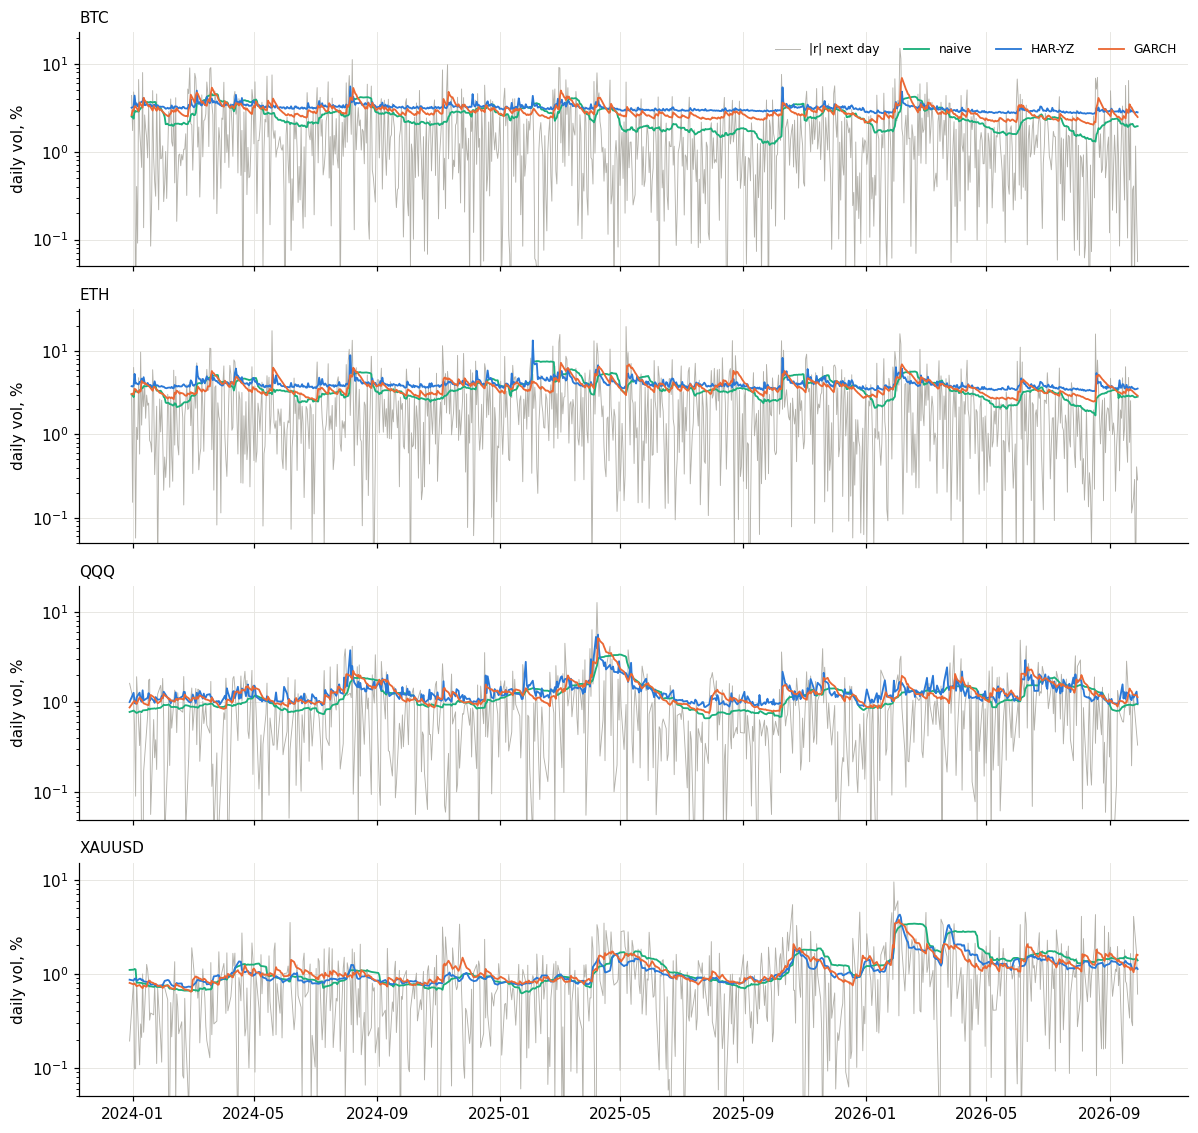

In [11]:
CC = {'realized': '#b4b2ab', 'HAR-YZ': '#2a78d6', 'GARCH': '#eb6834', 'naive': '#1baf7a'}
fig, axes = plt.subplots(len(ASSETS), 1, figsize=(11, 2.6 * len(ASSETS)), sharex=True)
for ax, s in zip(axes, ASSETS):
    f = comp[s][comp[s].split == 'test']
    ax.plot(f.index, np.sqrt(f.realized), color=CC['realized'], lw=0.6, label='|r| next day')
    for m in ['naive', 'HAR-YZ', 'GARCH']:
        ax.plot(f.index, np.sqrt(f[m]), color=CC[m], lw=1.2, label=m)
    ax.set_yscale('log'); ax.set_ylim(bottom=0.05)
    ax.set_title(s, loc='left', fontsize=10); ax.set_ylabel('daily vol, %')
axes[0].legend(loc='upper right', ncol=4, frameon=False, fontsize=8)
fig.tight_layout()

## Findings: GARCH vs HAR-YZ (run 2026-11-01; target r², provisional)

QLIKE vs naive (lower = better), annual walk-forward:

| Asset | Train HAR-YZ | Train GARCH | Test HAR-YZ | Test GARCH | Test winner |
|---|---:|---:|---:|---:|---|
| BTC | −0.027 | −0.032 | **+0.058** | −0.021 | GARCH (all 3 test folds) |
| ETH | +0.063 | +0.029 | −0.098 | −0.086 | Tie |
| QQQ | +0.044 | +0.045 | −0.100 | −0.047 | HAR-YZ (all 3 test folds) |
| XAUUSD | −0.041 | −0.007 | −0.047 | −0.042 | Tie |

- **GARCH fixes HAR's problem in calm crypto years.** Crypto HAR stays near its long-run average and loses badly when volatility is low (BTC 2023 +0.095, 2025 +0.141 vs naive). GARCH reacts to each day's return, so in those years it scores about the same as naive (+0.001, +0.021). For BTC, GARCH beats HAR in 5 of 6 folds.
- **For QQQ, HAR-YZ is clearly better on test** (−0.100 vs −0.047, every test fold). On train, both lose to naive by about the same amount.
- **ETH and gold: no meaningful difference** between the two on test.
- **No single winner across assets**, which the guide allows. Differences are not yet tested for significance (Diebold–Mariano pending). The target is still provisional.
- Forecasts saved to `forecasts/<SYM>-GARCH11.csv` (same format as HAR-YZ).